# Notebook 14 – EDA Mini Challenge (With Answers)
## `14_EDA_Mini_Challenge_Answers.ipynb`

This is the **worked solution** to the EDA Mini Challenge. Run the cells from top to bottom.

The dataset is a generated retail customer dataset. It is intentionally imperfect so you can practice identifying missing values, duplicates, invalid values, inconsistent categories, outliers, distributions, and relationships.

**Learning tip:** First attempt the original `14_EDA_Mini_Challenge.ipynb` without looking at this file. Then compare your findings with these answers.

**Important:** This notebook identifies issues and recommends possible preprocessing. It does not perform full preprocessing or automatically remove/fix records.

## 1. Load the challenge dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

rng = np.random.default_rng(42)
n = 240

customer_id = [f"C{i:04d}" for i in range(1, n + 1)]
age = rng.normal(36, 11, n).round().astype(float)
income = rng.normal(52000, 16000, n).round(0)
visits = rng.poisson(5, n).astype(float)
spend = (visits * rng.normal(85, 18, n) + rng.normal(100, 70, n)).round(2)
segment = rng.choice(["Regular", "Premium", "Budget"], size=n, p=[0.55, 0.2, 0.25]).astype(object)
region = rng.choice(["North", "South", "East", "West"], size=n)
member = rng.choice(["Yes", "No"], size=n, p=[0.62, 0.38]).astype(object)
churn = rng.choice(["Yes", "No"], size=n, p=[0.22, 0.78]).astype(object)

challenge_df = pd.DataFrame({
    "customer_id": customer_id,
    "age": age,
    "annual_income": income,
    "visits_last_month": visits,
    "monthly_spend": spend,
    "customer_segment": segment,
    "region": region,
    "membership": member,
    "churn": churn
})

for col, idx in [("age", [4, 18, 77]), ("annual_income", [9, 51, 109, 180]),
                 ("customer_segment", [13, 88, 143]), ("region", [31, 95])]:
    challenge_df.loc[idx, col] = np.nan

challenge_df.loc[22, "age"] = 145
challenge_df.loc[61, "annual_income"] = -5000
challenge_df.loc[120, "monthly_spend"] = 12500
challenge_df.loc[33, "customer_segment"] = " premium "
challenge_df.loc[72, "region"] = "south"
challenge_df.loc[200, "visits_last_month"] = -2
challenge_df = pd.concat([challenge_df, challenge_df.iloc[[5, 20, 42]]], ignore_index=True)
challenge_df["annual_income"] = challenge_df["annual_income"].map(
    lambda x: f"{x:.0f}" if pd.notna(x) else x
)
challenge_df.loc[17, "annual_income"] = "unknown"

df = challenge_df.copy()
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (243, 9)


,customer_id,age,annual_income,visits_last_month,monthly_spend,customer_segment,region,membership,churn
0,C0001,39.0,37970,10.0,1011.08,Premium,South,No,No
1,C0002,25.0,50492,2.0,179.61,Budget,East,Yes,No
2,C0003,44.0,23876,3.0,290.76,Premium,North,No,No
3,C0004,46.0,28527,4.0,516.17,Premium,East,Yes,Yes
4,C0005,NaN,86068,3.0,304.12,Regular,North,No,Yes


## 2. Task 1 – Understand the dataset
**Answer:** Each row is intended to represent one customer. The dataset belongs to the retail/customer analytics domain. It contains customer demographics, purchasing activity, membership information, region, and a churn indicator. `churn` is the likely classification target if the business objective is to predict whether a customer leaves.

In [2]:
print("First five rows:")
display(df.head())
print("Last five rows:")
display(df.tail())
print("Rows and columns:", df.shape)
print("Possible target: churn")
print("Unit of observation: one customer record")

First five rows:


,customer_id,age,annual_income,visits_last_month,monthly_spend,customer_segment,region,membership,churn
0,C0001,39.0,37970,10.0,1011.08,Premium,South,No,No
1,C0002,25.0,50492,2.0,179.61,Budget,East,Yes,No
2,C0003,44.0,23876,3.0,290.76,Premium,North,No,No
3,C0004,46.0,28527,4.0,516.17,Premium,East,Yes,Yes
4,C0005,NaN,86068,3.0,304.12,Regular,North,No,Yes


Last five rows:


,customer_id,age,annual_income,visits_last_month,monthly_spend,customer_segment,region,membership,churn
238,C0239,24.0,52101,4.0,527.39,Regular,North,Yes,No
239,C0240,30.0,93563,3.0,340.10,Regular,West,Yes,No
240,C0006,22.0,31401,8.0,851.62,Budget,South,No,No
241,C0021,34.0,48189,5.0,562.39,Premium,East,Yes,No
242,C0043,29.0,66839,6.0,520.24,Regular,North,No,No


Rows and columns: (243, 9)
Possible target: churn
Unit of observation: one customer record


## 3. Task 2 – Inspect the structure
**Answer:** The dataset has 243 rows and 9 columns. It includes an ID, numerical measurements, and categorical fields. Three additional rows were appended as duplicate records.

In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDataFrame information:")
df.info()
print("\nSummary:")
display(df.describe(include="all").T)

Shape: (243, 9)

Columns: ['customer_id', 'age', 'annual_income', 'visits_last_month', 'monthly_spend', 'customer_segment', 'region', 'membership', 'churn']

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        243 non-null    str    
 1   age                240 non-null    float64
 2   annual_income      239 non-null    str    
 3   visits_last_month  243 non-null    float64
 4   monthly_spend      243 non-null    float64
 5   customer_segment   240 non-null    str    
 6   region             241 non-null    str    
 7   membership         243 non-null    str    
 8   churn              243 non-null    str    
dtypes: float64(3), str(6)
memory usage: 23.5 KB

Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,243,240,C0006,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,240.0,NaN,NaN,NaN,35.820833,12.065251,12.0,29.0,35.0,41.0,145.0
annual_income,239,235,31401,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visits_last_month,243.0,NaN,NaN,NaN,5.032922,2.306778,-2.0,3.0,5.0,6.0,13.0
monthly_spend,243.0,NaN,NaN,NaN,575.0893,797.742337,-66.69,371.44,519.81,661.535,12500.0
customer_segment,240,4,Regular,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,241,5,East,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
membership,243,2,Yes,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn,243,2,No,179,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Task 3 – Identify data types
**Answer:** `annual_income` is stored as text even though it represents a numerical amount. This is a data-type issue. It also contains the text value `unknown`. Other columns have expected numeric or categorical types, although values still need validation.

In [4]:
display(df.dtypes.to_frame("data_type"))
print("Sample annual_income values:")
display(df["annual_income"].drop_duplicates().head(12))
print("\nSample values by column:")
for col in df.columns:
    print(f"{col}: {df[col].dropna().astype(str).unique()[:8]}")

,data_type
customer_id,str
age,float64
annual_income,str
visits_last_month,float64
monthly_spend,float64
customer_segment,str
region,str
membership,str
churn,str


Sample annual_income values:


0     37970
1     50492
2     23876
3     28527
4     86068
5     31401
6     34451
7     81391
8     98481
9       NaN
10    46108
11    57465
Name: annual_income, dtype: str


Sample values by column:
customer_id: <ArrowStringArray>
['C0001', 'C0002', 'C0003', 'C0004', 'C0005', 'C0006', 'C0007', 'C0008']
Length: 8, dtype: str
age: <ArrowStringArray>
['39.0', '25.0', '44.0', '46.0', '22.0', '37.0', '33.0', '36.0']
Length: 8, dtype: str
annual_income: <ArrowStringArray>
['37970', '50492', '23876', '28527', '86068', '31401', '34451', '81391']
Length: 8, dtype: str
visits_last_month: <ArrowStringArray>
['10.0', '2.0', '3.0', '4.0', '8.0', '6.0', '5.0', '12.0']
Length: 8, dtype: str
monthly_spend: <ArrowStringArray>
['1011.08', '179.61', '290.76', '516.17', '304.12', '851.62', '308.41', '904.62']
Length: 8, dtype: str
customer_segment: <ArrowStringArray>
['Premium', 'Budget', 'Regular', ' premium ']
Length: 4, dtype: str
region: <ArrowStringArray>
['South', 'East', 'North', 'West', 'south']
Length: 5, dtype: str
membership: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
churn: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


## 5. Task 4 – Identify missing values
**Answer:** Missing values were deliberately introduced in `age`, `annual_income`, `customer_segment`, and `region`. Use both counts and percentages to compare their impact. The exact percentages are calculated below.

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)

,missing_count,missing_percent
annual_income,4,1.65
customer_segment,3,1.23
age,3,1.23
region,2,0.82
customer_id,0,0.00
monthly_spend,0,0.00
visits_last_month,0,0.00
membership,0,0.00
churn,0,0.00


## 6. Task 5 – Identify duplicate records
**Answer:** Three duplicate rows were appended. `duplicated()` detects fully repeated rows; duplicate customer IDs should also be checked separately because repeated IDs do not always mean identical records in real transaction datasets.

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values("customer_id"))
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

Exact duplicate rows: 3


,customer_id,age,annual_income,visits_last_month,monthly_spend,customer_segment,region,membership,churn
5,C0006,22.0,31401,8.0,851.62,Budget,South,No,No
240,C0006,22.0,31401,8.0,851.62,Budget,South,No,No
20,C0021,34.0,48189,5.0,562.39,Premium,East,Yes,No
241,C0021,34.0,48189,5.0,562.39,Premium,East,Yes,No
42,C0043,29.0,66839,6.0,520.24,Regular,North,No,No
242,C0043,29.0,66839,6.0,520.24,Regular,North,No,No


Duplicate customer IDs: 3


## 7. Task 6 – Analyze numerical features
**Answer:** Convert income to numeric only for analysis using `pd.to_numeric(errors='coerce')`. This creates a temporary numeric series; it does not overwrite or clean the original column. Compare mean and median and inspect minimum values for impossible entries.

In [7]:
analysis_df = df.copy()
analysis_df["annual_income_numeric"] = pd.to_numeric(
    analysis_df["annual_income"], errors="coerce"
)

numeric_cols = ["age", "annual_income_numeric", "visits_last_month", "monthly_spend"]
numeric = analysis_df[numeric_cols]

summary = numeric.describe().T
summary["median"] = numeric.median()
summary["mode"] = numeric.mode().iloc[0]
summary["variance"] = numeric.var()
summary["skewness"] = numeric.skew()
display(summary)

,count,mean,std,min,25%,50%,75%,max,median,mode,variance,skewness
age,240.0,35.820833,12.065251,12.00,29.00,35.00,41.000,145.0,35.00,32.00,1.455703e+02,3.231312
annual_income_numeric,238.0,52252.726891,16692.235772,-5000.00,41329.25,52967.50,63576.750,98481.0,52967.50,31401.00,2.786307e+08,-0.158282
visits_last_month,243.0,5.032922,2.306778,-2.00,3.00,5.00,6.000,13.0,5.00,4.00,5.321226e+00,0.460548
monthly_spend,243.0,575.089300,797.742337,-66.69,371.44,519.81,661.535,12500.0,519.81,520.24,6.363928e+05,13.910331


## 8. Task 7 – Analyze categorical features
**Answer:** Inspect frequency tables and percentages. The dataset includes inconsistent labels such as ` premium ` and `south`; these should be documented for later standardization, not silently changed during EDA.

In [8]:
categorical_cols = ["customer_segment", "region", "membership", "churn"]
for col in categorical_cols:
    print(f"\\n{col} – unique values: {df[col].nunique(dropna=True)}")
    counts = df[col].value_counts(dropna=False)
    table = pd.DataFrame({
        "count": counts,
        "percentage": (counts / len(df) * 100).round(2)
    })
    display(table)

\ncustomer_segment – unique values: 4


,count,percentage
customer_segment,,
Regular,124,51.03
Budget,62,25.51
Premium,53,21.81
NaN,3,1.23
premium,1,0.41


\nregion – unique values: 5


,count,percentage
region,,
East,68,27.98
North,65,26.75
West,56,23.05
South,51,20.99
NaN,2,0.82
south,1,0.41


\nmembership – unique values: 2


,count,percentage
membership,,
Yes,160,65.84
No,83,34.16


\nchurn – unique values: 2


,count,percentage
churn,,
No,179,73.66
Yes,64,26.34


## 9. Task 8 – Detect outliers
**Answer:** The IQR method flags potential statistical outliers. The intentionally unusual records include age 145, income -5000, and monthly spend 12500. A negative visit count is also an invalid domain value, even if it is not detected as an IQR outlier.

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
0,age,29.00,41.000,12.000,11.0000,59.0000,4
1,annual_income_numeric,41329.25,63576.750,22247.500,7958.0000,96948.0000,2
2,visits_last_month,3.00,6.000,3.000,-1.5000,10.5000,5
3,monthly_spend,371.44,661.535,290.095,-63.7025,1096.6775,4


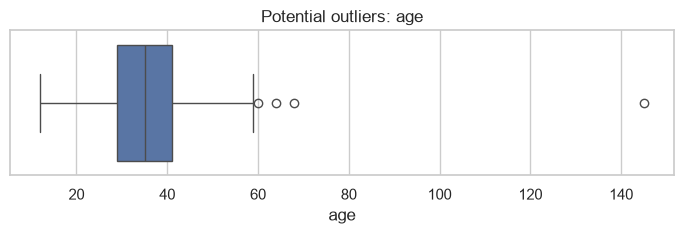

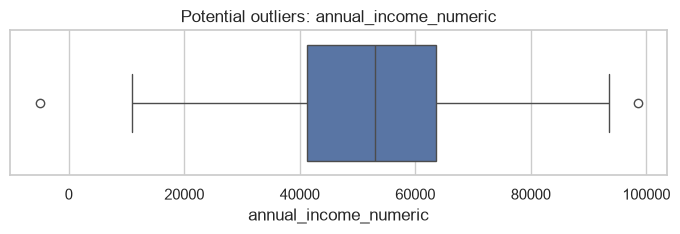

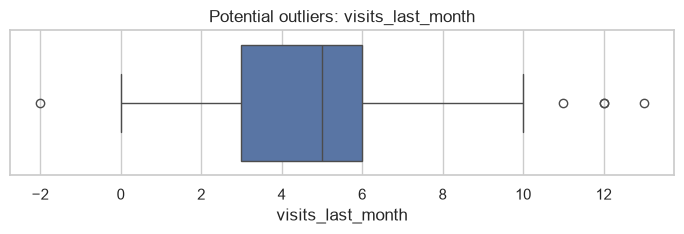

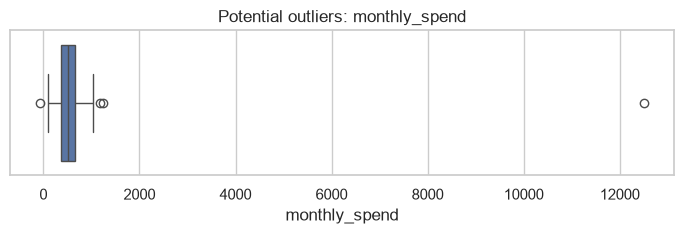

Negative visit counts:


,customer_id,age,annual_income,visits_last_month,monthly_spend,customer_segment,region,membership,churn
200,C0201,40.0,48972,-2.0,476.68,Regular,North,Yes,Yes


In [9]:
outlier_results = []
for col in numeric_cols:
    s = numeric[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (numeric[col] < lower) | (numeric[col] > upper)
    outlier_results.append({
        "feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(mask.sum())
    })
display(pd.DataFrame(outlier_results))

for col in numeric_cols:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=numeric[col])
    plt.title(f"Potential outliers: {col}")
    plt.tight_layout()
    plt.show()

print("Negative visit counts:")
display(df[df["visits_last_month"] < 0])

## 10. Task 9 – Analyze distributions
**Answer:** Histograms and skewness help describe shape. The very high monthly spend value can stretch the distribution. Interpret skewness together with histograms and domain knowledge; a single statistic is not enough.

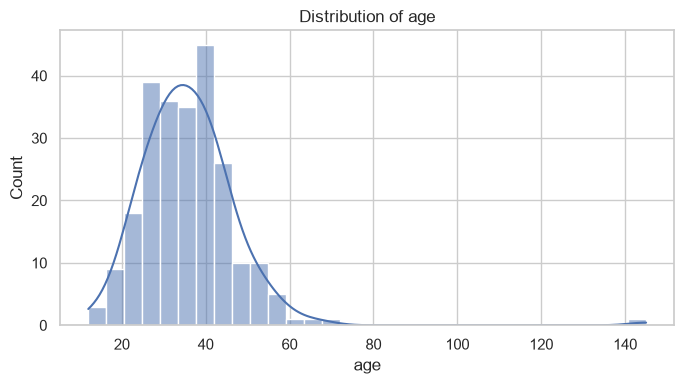

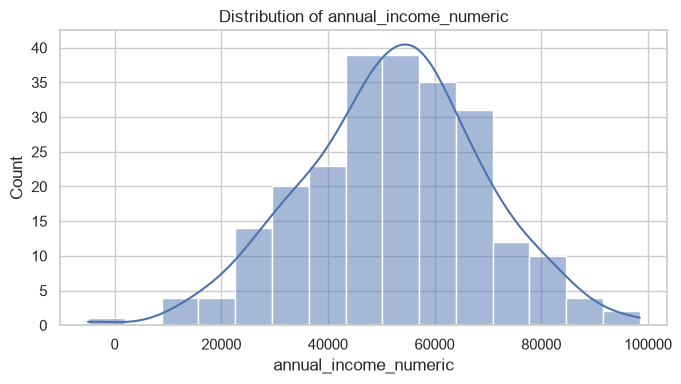

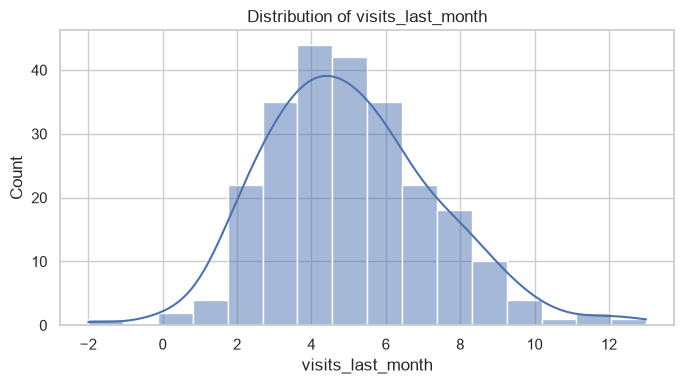

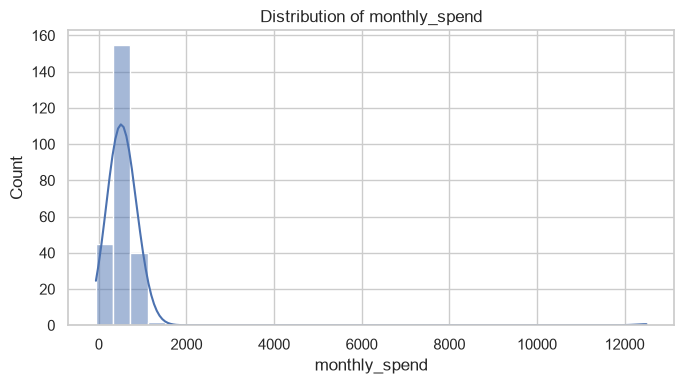

,skewness,kurtosis
age,3.231312,27.096711
annual_income_numeric,-0.158282,0.201587
visits_last_month,0.460548,0.548781
monthly_spend,13.910331,208.484888


In [10]:
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(numeric[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

display(pd.DataFrame({
    "skewness": numeric.skew(),
    "kurtosis": numeric.kurtosis()
}))

## 11. Task 10 – Analyze correlations
**Answer:** Correlation can be calculated after making a temporary numeric view. A correlation matrix only measures linear association between numeric variables. It does not prove causation.

,age,annual_income_numeric,visits_last_month,monthly_spend
age,1.000000,-0.049360,-0.000402,-0.043287
annual_income_numeric,-0.049360,1.000000,0.036065,-0.014158
visits_last_month,-0.000402,0.036065,1.000000,0.167401
monthly_spend,-0.043287,-0.014158,0.167401,1.000000


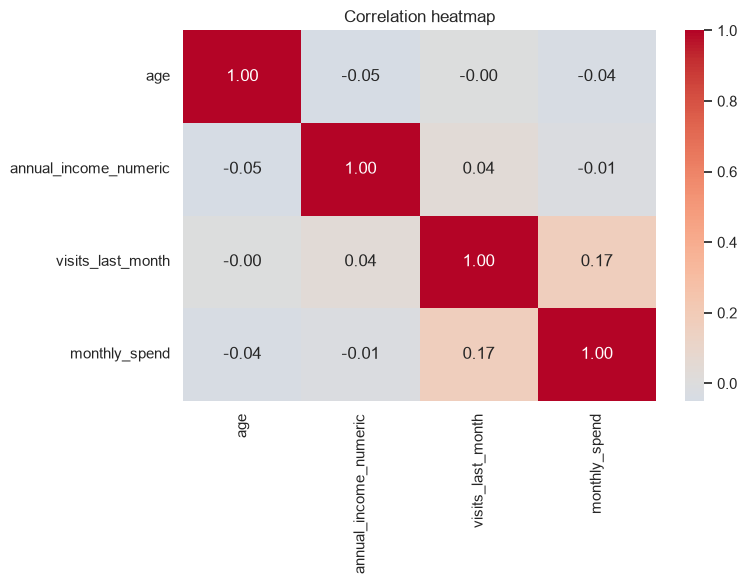

In [11]:
corr = numeric.corr(numeric_only=True)
display(corr)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

## 12. Task 11 – Create meaningful visualizations
**Answer:** The following plots cover numerical distributions, category counts, an outlier-oriented box plot, and relationships. Chart conclusions should be written in terms of observed evidence.

In [ ]:
# Numerical distributions
for col in ["age", "monthly_spend"]:
    plt.figure(figsize=(7, 4))
    sns.histplot(numeric[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

# Categorical count plot
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="customer_segment", order=df["customer_segment"].value_counts().index)
plt.title("Customer segment counts (including inconsistent labels)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Box plot
plt.figure(figsize=(7, 3))
sns.boxplot(x=numeric["monthly_spend"])
plt.title("Monthly spend box plot")
plt.tight_layout()
plt.show()

# Relationship plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=analysis_df, x="visits_last_month", y="monthly_spend", hue="churn")
plt.title("Visits last month vs monthly spend by churn")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Numerical feature correlation")
plt.tight_layout()
plt.show()

## 13. Task 12 – Identify important patterns
**Example answer:** (1) Monthly spend and visits can be compared to investigate whether more frequent customers spend more. (2) The extreme monthly spend value may dominate summary statistics and should be validated. (3) Missingness and inconsistent category labels may affect group comparisons. Use the outputs above to add exact values and avoid claiming relationships that the charts do not support.

In [ ]:
# A compact evidence table to help document patterns
pattern_checks = {
    "average_monthly_spend_by_churn": df.assign(
        monthly_spend=pd.to_numeric(df["monthly_spend"], errors="coerce")
    ).groupby("churn")["monthly_spend"].agg(["count", "mean", "median"]),
    "average_visits_by_churn": df.groupby("churn")["visits_last_month"].agg(["count", "mean", "median"])
}
for title, result in pattern_checks.items():
    print(title)
    display(result)

## 14. Task 13 – Business insights
**Example answer:** (1) Customer visit frequency and monthly spend are useful measures for understanding purchasing activity. (2) Churn groups can be compared on spend, visits, membership, and segment to identify possible retention signals. (3) Data-quality issues such as missing income and inconsistent segment names should be resolved before management relies on customer segment comparisons. These are exploratory observations, not proof of causes.

In [ ]:
# Compare a few business metrics by churn.
business_view = df.copy()
business_view["annual_income_numeric"] = pd.to_numeric(
    business_view["annual_income"], errors="coerce"
)
display(
    business_view.groupby("churn")[
        ["age", "annual_income_numeric", "visits_last_month", "monthly_spend"]
    ].agg(["count", "mean", "median"]).round(2)
)

## 15. Task 14 – Potential data problems
**Answer:** The main issues intentionally present are missing values, exact duplicate rows, income stored as text, the `unknown` income entry, inconsistent category spelling/whitespace, negative income, negative visit count, and extreme age/spend values. Confirm each issue with the data owner before changing records.

In [ ]:
issues = pd.DataFrame([
    ["Missing values", "age, annual_income, customer_segment, region", "Null counts shown in missing-value table", "Reduced usable data / biased analysis", "Why are values missing?"],
    ["Exact duplicates", "Entire records", "duplicated() identifies appended rows", "Double counting", "Are these accidental duplicate imports?"],
    ["Wrong data type", "annual_income", "Income values stored as strings", "Numeric analysis may fail", "What is the expected currency/format?"],
    ["Unparseable value", "annual_income", "'unknown' text value", "Numeric conversion produces missing value", "Does unknown mean unavailable or invalid?"],
    ["Inconsistent labels", "customer_segment, region", "' premium ', 'south'", "Splits one group into multiple categories", "What is the approved category list?"],
    ["Invalid domain values", "annual_income, visits_last_month", "Negative income and negative visits", "Misleading business metrics", "Are these entry or system errors?"],
    ["Potential outliers", "age, monthly_spend", "Age 145 and spend 12500", "Can distort statistics/models", "Are these valid exceptional customers?"]
], columns=["problem", "affected_columns", "evidence", "possible_impact", "what_to_confirm"])
display(issues)

## 16. Task 15 – Recommendations for the next preprocessing stage
**Answer:** Prioritize validation and data understanding before transformations. Do not blindly delete outliers or impute all missing values with the mean.

| Priority | Recommended action | Reason / validation |
|---|---|---|
| 1 | Confirm row meaning and duplicate policy | Determine whether repeated records are accidental |
| 2 | Correct `annual_income` data type after handling invalid text | Numeric analysis and modeling require a valid numeric representation |
| 3 | Investigate negative income and visit counts | These may violate business rules |
| 4 | Standardize category labels using an approved category mapping | Avoid duplicate categories caused by capitalization or whitespace |
| 5 | Choose missing-value treatment per column | Consider missingness reason, distribution, and business meaning |
| 6 | Investigate extreme age and spend values | Confirm valid exceptional cases versus data-entry errors |
| 7 | Encode categorical features if required by the selected model | Choose encoding based on category meaning and model |
| 8 | Consider scaling numerical features if the model is scale-sensitive | Scaling is not required for every algorithm |
| 9 | Consider feature engineering such as spend per visit, if meaningful | Validate business logic and prevent target leakage |
| 10 | Check target definition and class balance | Ensure churn labels are reliable and model evaluation is appropriate |

## 17. Final challenge report – Example conclusion

The dataset represents customer-level retail information and includes demographic, purchasing, membership, regional, and churn fields. Initial inspection identifies data-quality concerns that should be addressed before machine-learning development: missing values, duplicate records, a numeric field stored as text, inconsistent category labels, invalid negative values, and potentially extreme numerical observations.

The analysis should next validate the business meaning of each record and the target definition. The preprocessing sprint should prioritize duplicate validation, income type correction, investigation of invalid values, category standardization, and a documented missing-value strategy. Outlier treatment should be based on business validation rather than automatic removal. Candidate features and model preparation steps should be considered only after these checks.

**Note:** The exact statistical values and plots are generated by the code cells above. Use those outputs when writing a final report for a different dataset.